# Ablation RF-v1 đến RF-v4

Mở từ thư mục dự án với kernel của môi trường dự án. Các ô đọc config, bảng và hình đã công bố.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "reports/stage5_inputs.json").is_file())
sys.path.insert(0, str(root))
from src.wrmsse_stage5 import STAGE2, STAGE3, STAGE4, SELECTED, TABLES, csv, read, check_gates
check_gates()

def table(name):
    return csv(TABLES / (name + ".csv"))

def figure(number):
    path, = (root / "reports/figures").glob(f"{number:02d}_*.png")
    display(Image(filename=str(path), width=950))


Dùng cùng siêu tham số của RF-04 để kiểm tra các tầng đặc trưng mở rộng. RF-v2 bổ sung tỷ lệ không bán, RF-v3 bổ sung số ngày bán khác 0, RF-v4 thêm recency. RF-v1 cho WRMSSE thấp nhất và được giữ làm bộ cơ sở cho vòng nâng cao.

,experiment,logical,encoded,validation_wrmsse,reuse
5,ABL_rf_v1,14,3081,0.675729,True
6,ABL_rf_v2,16,3083,0.680816,False
7,ABL_rf_v3,17,3084,0.684216,False
8,ABL_rf_v4,18,3085,0.685052,False


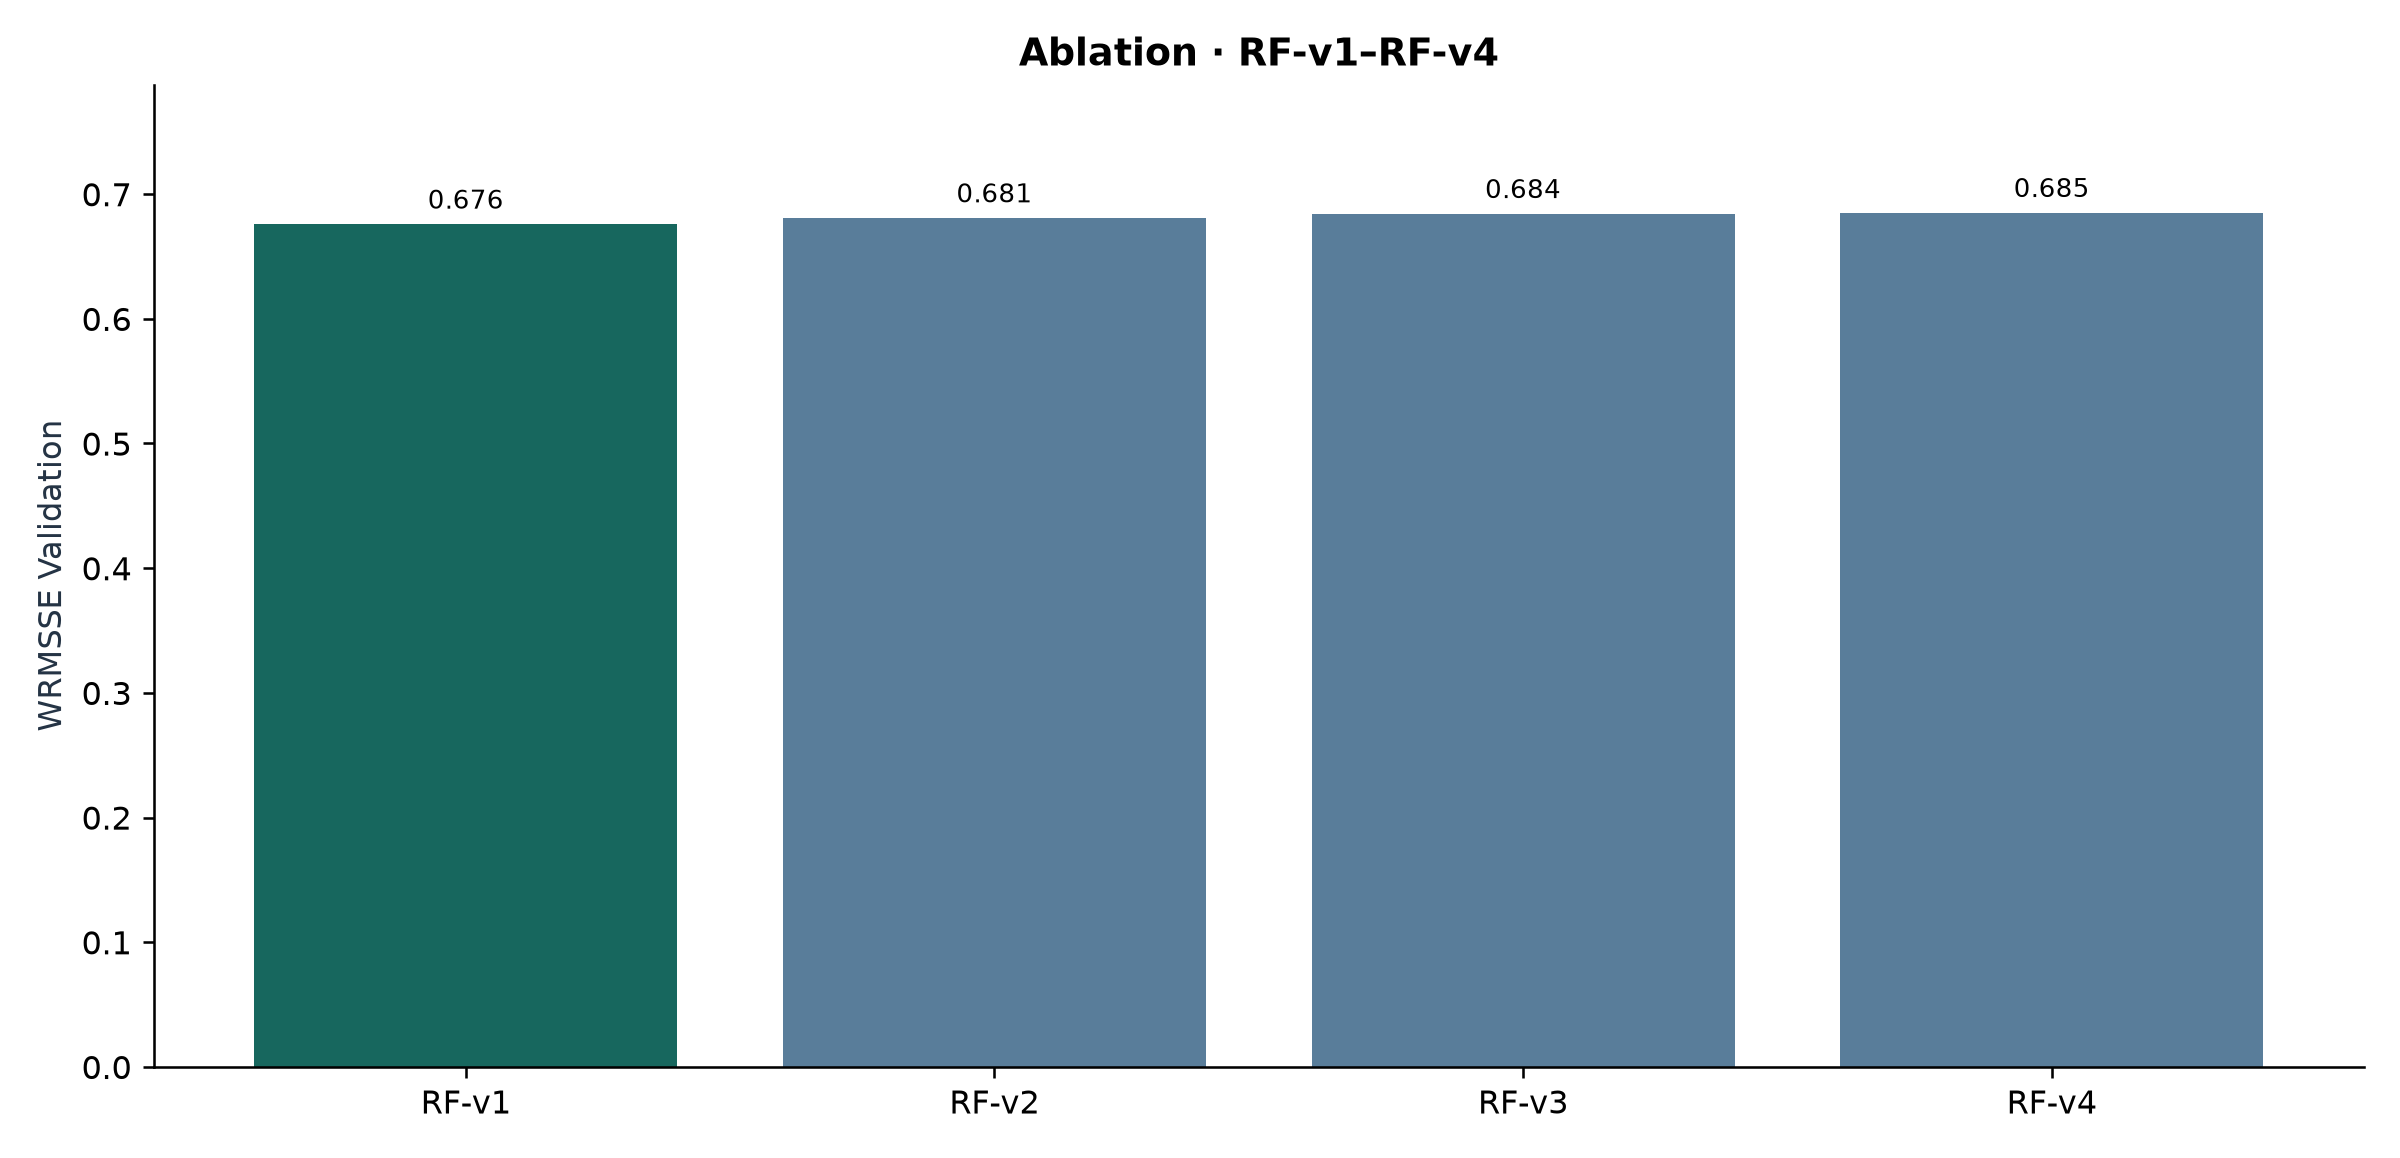

In [2]:
ablation = table("experiment_results").query("group == 'ablation'").sort_values("validation_wrmsse")
display(ablation[["experiment", "logical", "encoded", "validation_wrmsse", "reuse"]])
figure(4)